# 15 · fUSI preprocessing and leakage-safe splits

Two things decide whether a fUSI decoder result can be trusted: that the **same arithmetic**
runs offline (training, Dask/Zarr) and online (the real-time actors), and that **no information
from held-out data** reaches training. This notebook covers both:

1. the preprocessing chain, `workloads/fusi_realtime/preprocess.py`, and the proof that its
   streaming and batch forms agree;
2. the Zarr + Dask batch path, `batch.py`;
3. block-based splits and the executable leakage checks in `splits.py`, shown passing on a
   correct split and failing on deliberately leaky ones;
4. a measurement of how much a leaky split inflates accuracy on this synthetic data.

Sessions are simulated at 8³ voxels so that stored data stays at tens of MB; everything lives
in a temporary directory that the last cell deletes.

## Conceptual model

**Chain** (per volume, causal):

$$\text{IQ ensemble} \xrightarrow{\text{SVD clutter filter}} P \xrightarrow{\log} y \xrightarrow{-\,\text{EMA baseline}} \tilde y \xrightarrow{-\,R\beta} e \xrightarrow{(\cdot-\mu)/\sigma} z$$

* Clutter filter (Demene et al. 2015): remove the top singular component(s) of the
  ensemble × voxel matrix, then average $|\cdot|^2$ over the ensemble. Computed from the small
  Gram matrix $MM^H$, so cost is $O(n_\text{ens}^2 V)$.
* Drift: subtract a *causal* exponential moving average ($\tau$ = 20 s). Causal so that offline
  features equal what the hot path can compute.
* RETROICOR (Glover, Li, Ress 2000): per-voxel linear regression on $\cos/\sin(m\varphi)$ of the
  recorded cardiac and respiratory phases, $m = 1..2$. The fitted $\beta$, $\mu$, $\sigma$ form
  the **preprocessor state**.
* The state is *fitted* (on train only), then *frozen* and applied to every split and to the
  real-time path. It is saved with a hash and the list of `(session, start, end)` blocks it saw,
  which is what the leakage check audits.

**Leakage.** Neighbouring volumes at 10 Hz are nearly identical, and blood volume stays
correlated for seconds. A split that places neighbours on both sides measures memorisation
(Kapoor and Narayanan 2023; Roberts et al. 2017). The split unit is a block of frames (a whole
session by default); windows never cross block edges; checks are pure functions of the split
*as data*, so a wrong split can be constructed by hand and shown to fail.

In [1]:
import os, sys, tempfile, time, warnings
from pathlib import Path

os.environ.setdefault("MLFLOW_DISABLE_AGENT_HINT", "1")
os.environ.setdefault("ML_LOG_LEVEL", "WARNING")   # keep structlog output out of the notebook
os.environ.setdefault("RAY_DEDUP_LOGS", "1")
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=DeprecationWarning)
warnings.filterwarnings("ignore", category=FutureWarning)
os.environ.setdefault("RAY_USAGE_STATS_ENABLED", "0")
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

np.set_printoptions(precision=4, suppress=True)
pd.set_option("display.precision", 4)
pd.set_option("display.width", 120)
plt.rcParams.update({"figure.dpi": 80, "figure.figsize": (7.5, 3.6), "axes.grid": True,
                     "grid.alpha": 0.3})

# Every artifact this notebook creates lives in a fresh temp dir -- never in the repo's
# data/, artifacts/ or mlflow.db.
WORK = Path(tempfile.mkdtemp(prefix="nb15_"))
T0 = time.perf_counter()
print("workspace:", WORK)

workspace: /var/folders/vx/0jy3t_qx56q4d0qpnmgs008r0000gn/T/nb15_2wzbp6ru


In [2]:
from ml_platform.config import PlatformConfig
from ml_platform.workloads.fusi_realtime import preprocess as PP, splits as SP, batch as B, sim as S
from ml_platform.workloads.fusi_realtime.config import FusiConfig
from ml_platform.workloads.fusi_realtime.dataset import DECODER_INPUTS

cfg = FusiConfig.for_tests()                       # tiny sizes (8^3 grid, short windows) ...
cfg.sim = cfg.sim.model_copy(update={"plan_s": 3.0, "rest_s": 1.5, "n_ensemble": 8})   # ... with the default task timing and ensemble
sc, pc, spc = cfg.sim, cfg.preprocess, cfg.split
GRID, FS = tuple(sc.grid), sc.frame_rate_hz
print("grid", GRID, "| ensemble", sc.n_ensemble, "| clutter rank", pc.clutter_rank,
      "| drift tau", pc.drift_tau_s, "s | RETROICOR order", pc.retroicor_order)

grid (8, 8, 8) | ensemble 8 | clutter rank 1 | drift tau 20.0 s | RETROICOR order 2


## 1 · The chain, stage by stage

Simulate 800 frames. The preprocessor is **fitted on frames 0-499 and evaluated on 500-799**, to
show how much physiological variance the frozen regression removes from data it has not seen.

held-out variance removed by RETROICOR: median over all 512 voxels 3.7%; over the 25% most pulsatile voxels 15.9% (speckle and the task response are not removable)
z-scored features on the fit half: mean +0.000, std 1.000;  held-out half: mean +0.108, std 1.041


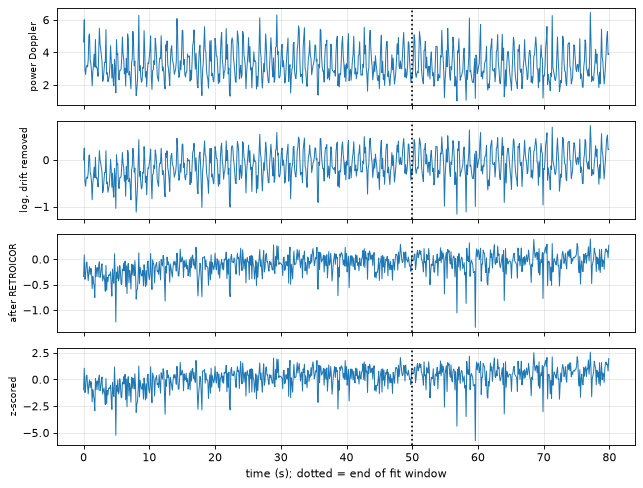

In [3]:
NF = 800
sim = S.FusiSimulator(sc, subject=0, session=0, grid=GRID, emit="iq")
frames = sim.run(NF)
iq = np.stack([f.iq for f in frames])                                  # (T, ens, x, y, z)
card = np.array([f.cardiac_phase for f in frames]); resp = np.array([f.respiratory_phase for f in frames])

power = PP.clutter_filter(iq, pc.clutter_rank)                         # (T, x, y, z)
y = PP.detrended_log(power, FS, pc)                                    # log + causal EMA drift removal, (T, V)
fit_sl, ev_sl = slice(0, 500), slice(500, NF)
state = PP.fit_preprocessor([("demo", 0, 500, y[fit_sl], card[fit_sl], resp[fit_sl])],
                            grid=GRID, frame_rate_hz=FS, cfg=pc)
z = PP.apply_fitted(y, card, resp, state)                              # RETROICOR + z-score

# variance of drift-free log power before / after RETROICOR, held-out half only
R = PP.retroicor_regressors(card, resp, pc.retroicor_order)
resid = y - R @ state.coef.astype(np.float64)
v_before, v_after = y[ev_sl].var(0), resid[ev_sl].var(0)
gain = 1 - v_after / v_before
pulsatile = sim.anatomy.cardiac_map > np.quantile(sim.anatomy.cardiac_map, 0.75)
print(f"held-out variance removed by RETROICOR: median over all {y.shape[1]} voxels {np.median(gain):.1%}; "
      f"over the 25% most pulsatile voxels {np.median(gain[pulsatile]):.1%} (speckle and the task response are not removable)")
print(f"z-scored features on the fit half: mean {z[fit_sl].mean():+.3f}, std {z[fit_sl].std():.3f};  "
      f"held-out half: mean {z[ev_sl].mean():+.3f}, std {z[ev_sl].std():.3f}")

v = int(np.argmax(sim.anatomy.cardiac_map))
fig, ax = plt.subplots(4, 1, figsize=(8, 6.2), sharex=True); t = np.arange(NF) / FS
for a, (sig, nm) in zip(ax, ((power.reshape(NF, -1)[:, v], "power Doppler"), (y[:, v], "log, drift removed"),
                             (resid[:, v], "after RETROICOR"), (z[:, v], "z-scored"))):
    a.plot(t, sig, lw=0.9); a.set_ylabel(nm, fontsize=8); a.axvline(50, c="k", ls=":")
ax[-1].set_xlabel("time (s); dotted = end of fit window"); plt.tight_layout(); plt.show()

The cardiac ripple (1.2 Hz) dominates the voxel with the strongest pulsatility until
RETROICOR removes it; what is left is speckle plus the task response. The preprocessor
generalises across the fit boundary because the regressors are functions of the *recorded
phase*, not of time.

## 2 · Streaming equals batch

`StreamingPreprocessor.step` processes one volume with one piece of state (the drift
baseline); `batch_transform` does the whole session at once. Training uses the batch form,
deployment the streaming form, so any difference is a train/serve skew. The assert allows float round-off
(batched vs per-frame Gram-matrix eigendecomposition); the measured difference is printed.

In [4]:
pre = PP.StreamingPreprocessor(state)
t0 = time.perf_counter()
stream = np.stack([pre.step(f.iq, f.cardiac_phase, f.respiratory_phase).reshape(-1) for f in frames])
t_stream = (time.perf_counter() - t0) / len(frames) * 1e3
batch = PP.batch_transform(power, card, resp, state).reshape(NF, -1)

diff = np.abs(stream - batch)
print(f"max |streaming - batch| = {diff.max():.2e}   mean = {diff.mean():.2e}   (features have unit scale)")
assert diff.max() < 1e-4
# the causal drift state is the only memory: reset it and the first frames change
pre.reset()
first = pre.step(frames[0].iq, frames[0].cardiac_phase, frames[0].respiratory_phase).reshape(-1)
print(f"after reset(), frame 0 reproduces: max diff {np.abs(first - batch[0]).max():.2e};  "
      f"streaming step costs {t_stream:.2f} ms/frame at {GRID}")

# State artifact round trip: saved with a hash, refused if altered
d = state.save(WORK / "pre_demo")
loaded = PP.PreprocessorState.load(d)
print("state hash:", state.state_hash()[:16], "| round trip identical:", loaded.state_hash() == state.state_hash())

max |streaming - batch| = 2.84e-14   mean = 6.94e-20   (features have unit scale)
after reset(), frame 0 reproduces: max diff 0.00e+00;  streaming step costs 0.05 ms/frame at (8, 8, 8)
state hash: b11ad5b522ced88a | round trip identical: True


## 3 · Sessions on disk: Zarr + Dask

Four sessions (120 s each, one subject) are written chunk by chunk to Zarr, storing the IQ
ensembles so that the clutter filter runs inside the Dask job. `write_simulated_session` is
write-once: the same key returns the existing store. Events (task labels) and truth
(evaluation only) go to separate Parquet files next to the raw data.

In [5]:
ROOT = WORK / "sessions"
N_FRAMES = 1200
stores = {}
for i in range(4):
    sm = S.FusiSimulator(sc, subject=0, session=100 + i, grid=GRID, emit="iq")
    key = f"sub00_ses{i:02d}"
    stores[key] = B.write_simulated_session(ROOT, sm, key=key, subject="sub00",
                                            n_frames=N_FRAMES, chunk_t=pc.chunk_t, store_iq=True)
mb = sum(p.stat().st_size for p in ROOT.rglob("*") if p.is_file()) / 1e6
print(f"{len(stores)} sessions x {N_FRAMES} frames written: {mb:.0f} MB under WORK")
print("files of one session:", sorted(p.name for p in (ROOT / "sub00_ses00").iterdir()))
ds = B.open_raw(stores["sub00_ses00"])
print(ds)

4 sessions x 1200 frames written: 146 MB under WORK
files of one session: ['events.parquet', 'manifest.json', 'raw.zarr', 'truth.parquet']
<xarray.Dataset> Size: 39MB
Dimensions:            (t: 1200, ens: 8, x: 8, y: 8, z: 8)
Coordinates:
  * t                  (t) float64 10kB 0.0 0.1 0.2 0.3 ... 119.7 119.8 119.9
Dimensions without coordinates: ens, x, y, z
Data variables:
    cardiac_phase      (t) float64 10kB dask.array<chunksize=(32,), meta=np.ndarray>
    respiratory_phase  (t) float64 10kB dask.array<chunksize=(32,), meta=np.ndarray>
    iq_re              (t, ens, x, y, z) float32 20MB dask.array<chunksize=(32, 8, 8, 8, 8), meta=np.ndarray>
    iq_im              (t, ens, x, y, z) float32 20MB dask.array<chunksize=(32, 8, 8, 8, 8), meta=np.ndarray>


The split is planned first, from session metadata only, and the preprocessor is then fitted on
the **train blocks of that plan**. With four sessions the default policy gives train = 0-1,
val = 2, test = 3.

In [6]:
metas = [SP.SessionMeta(k, s.subject, s.n_frames) for k, s in stores.items()]
plan = SP.make_split(metas, spc, FS)
print(plan.frame().assign(n=lambda d: d.end - d.start)[["session", "split", "start", "end", "n"]].to_string(index=False))
train_blocks = [(b.session, b.start, b.end) for b in plan.blocks_of("train")]

with B.dask_threads(4):
    t0 = time.perf_counter()
    state_d = B.fit_preprocessor_dask(stores, train_blocks, pc)
    t_fit = time.perf_counter() - t0
print(f"\nfit_preprocessor_dask on train only: {t_fit:.1f}s")
print("fit_blocks:", state_d.fit_blocks, "| fit_sessions:", state_d.fit_sessions, "| fit_n_frames:", state_d.fit_n_frames)
print("state hash:", state_d.state_hash()[:16])

    session split  start  end    n
sub00_ses00 train      0 1200 1200
sub00_ses01 train      0 1200 1200
sub00_ses02   val      0 1200 1200
sub00_ses03  test      0 1200 1200



fit_preprocessor_dask on train only: 0.3s
fit_blocks: (('sub00_ses00', 0, 1200), ('sub00_ses01', 0, 1200)) | fit_sessions: ('sub00_ses00', 'sub00_ses01') | fit_n_frames: 2400
state hash: d1b7dca07ef61fb5


The Dask path and the numpy reference (`fit_preprocessor`, normal equations accumulated block by
block) are two implementations of the same fit and must agree. Likewise the lazy transform of a
whole held-out session must equal `batch_transform`.

In [7]:
def session_arrays(key):
    ds = B.open_raw(stores[key])
    p = B.power_doppler(ds, pc.clutter_rank).compute().values
    return p, ds["cardiac_phase"].values, ds["respiratory_phase"].values

blocks_np = []
for k, a, b in train_blocks:
    p, c, r = session_arrays(k)
    blocks_np.append((k, a, b, PP.detrended_log(p, FS, pc)[a:b], c[a:b], r[a:b]))
state_np = PP.fit_preprocessor(blocks_np, grid=GRID, frame_rate_hz=FS, cfg=pc)
for name in ("coef", "mean", "std"):
    print(f"{name:5s} max |dask - numpy| = {np.abs(getattr(state_d, name) - getattr(state_np, name)).max():.2e}")

test_key = plan.sessions("test")[0]
with B.dask_threads(4):
    feats_dask = B.transform_session(stores[test_key], state_d).values
p, c, r = session_arrays(test_key)
feats_np = PP.batch_transform(p, c, r, state_d)
print(f"test session {test_key}: max |dask transform - numpy batch_transform| = {np.abs(feats_dask - feats_np).max():.2e}, "
      f"features {feats_dask.shape} mean {feats_dask.mean():+.3f} std {feats_dask.std():.3f}")
assert np.abs(feats_dask - feats_np).max() < 1e-3

coef  max |dask - numpy| = 0.00e+00
mean  max |dask - numpy| = 0.00e+00
std   max |dask - numpy| = 0.00e+00


test session sub00_ses03: max |dask transform - numpy batch_transform| = 0.00e+00, features (1200, 8, 8, 8) mean +0.022 std 1.026


Held-out features have mean ≈ 0 and std ≈ 1 only approximately: the normalisation statistics come
from the train sessions, and session-to-session gain differences are *not* removed. That is the
intended behaviour, since renormalising each test session on its own would use test data.

## 4 · A correct split passes every check

`make_windows` cuts decoder-input windows (12 frames, stride 6) that lie inside one block.
`split_checks` runs the six dataset-level checks; in the pipeline they are blocking Dagster asset
checks, so a failure stops promotion.

In [8]:
def table(checks):
    return pd.DataFrame([{"check": c.name, "passed": c.passed, "detail": c.detail} for c in checks]).set_index("check")

windows = SP.make_windows(plan, spc.window_frames, spc.window_stride)
print(windows.groupby("split").size().to_dict(), "windows per split;  hash", SP.windows_hash(windows)[:12])
good = SP.split_checks(plan, windows, fit_blocks=state_d.fit_blocks, inputs=DECODER_INPUTS, cfg=spc)
pd.set_option("display.max_colwidth", 200)
table(good)

{'test': 199, 'train': 398, 'val': 199} windows per split;  hash 5647661a579d


,passed,detail
check,,
sessions_disjoint,True,ok
subjects_disjoint,True,test subjects also in train/val: ['sub00'] (not required)
temporal_gap,True,no session shared between train and val/test
no_window_overlap,True,ok
preprocessing_fit_on_train_only,True,ok
feature_schema,True,ok


`subjects_disjoint` is only *required* for `hold_out="subject"`; with one simulated subject it is
informational (the detail names the shared subject, the check still passes).

## 5 · Deliberate leaks fail

**(a) Random window-level split inside one session.** One session is cut into overlapping
windows and each is assigned to train/val/test at random: the classic mistake.

In [9]:
cfg_tb = spc.model_copy(update={"hold_out": "time_block"})
plan_tb = SP.make_split(metas[:1], cfg_tb, FS)                    # the base plan: one session in time blocks
rng = np.random.default_rng(0)
starts = np.arange(0, N_FRAMES - spc.window_frames + 1, 6)
leaky_w = pd.DataFrame({"session": metas[0].key, "subject": "sub00",
                        "split": rng.choice(["train", "val", "test"], p=[0.7, 0.15, 0.15], size=len(starts)),
                        "start": starts, "end": starts + spc.window_frames})
res = SP.split_checks(plan_tb, leaky_w, fit_blocks=[(b.session, b.start, b.end) for b in plan_tb.blocks_of("train")],
                      inputs=DECODER_INPUTS, cfg=spc)
table(res)

,passed,detail
check,,
sessions_disjoint,True,time_block split: 1 sessions shared by design; guarded by temporal_gap
subjects_disjoint,True,test subjects also in train/val: ['sub00'] (not required)
temporal_gap,False,min gap -6 frames (sub00_ses00 train vs val); required 50
no_window_overlap,False,sub00_ses00 frame 24: train and val; sub00_ses00 frame 36: test and train; sub00_ses00 frame 48: val and train; sub00_ses00 frame 60: test and val; sub00_ses00 frame 72: train and test
preprocessing_fit_on_train_only,True,ok
feature_schema,True,ok


`temporal_gap` reports a negative minimum gap (train and test windows overlap in time) and
`no_window_overlap` finds frames owned by two splits and windows that leave their block.

**(b) Preprocessing fitted on all sessions.** Fitting RETROICOR and the z-score on train, val
and test frames lets test statistics shape the features. The state records what it saw, so the
check fails without inspecting any arrays.

In [10]:
all_blocks = [(k, 0, s.n_frames) for k, s in stores.items()]
with B.dask_threads(4):
    state_all = B.fit_preprocessor_dask(stores, all_blocks, pc)
c = SP.check_preprocessing_fit_on_train(state_all.fit_blocks, plan)
print(c.name, "->", "PASS" if c.passed else "FAIL"); print(c.detail)
print("hash of the train-only state:", state_d.state_hash()[:16], "| fit-on-all state:", state_all.state_hash()[:16])

preprocessing_fit_on_train_only -> FAIL
fitted on non-train frames: [('sub00_ses02', 0, 1200), ('sub00_ses03', 0, 1200)]
hash of the train-only state: d1b7dca07ef61fb5 | fit-on-all state: fddeb73ce901e308


**(c) Latent simulator state in the feature schema.** The decoder-input list is checked against
`SplitConfig.allowed_features` and against the simulator's latent column names. Neither
`latent_intent` nor an unlisted column such as `cue_direction` may be an input (the cue is a
label, and using it as a feature is a direct leak).

In [11]:
rows = []
for label, cols in (("decoder inputs", DECODER_INPUTS),
                    ("+ latent_intent", (*DECODER_INPUTS, "latent_intent")),
                    ("+ engagement", (*DECODER_INPUTS, "engagement")),
                    ("+ cue_direction", (*DECODER_INPUTS, "cue_direction"))):
    r = SP.check_feature_schema(cols, spc.allowed_features)
    rows.append({"inputs": label, "passed": r.passed, "detail": r.detail})
pd.DataFrame(rows).set_index("inputs")

,passed,detail
inputs,,
decoder inputs,True,ok
+ latent_intent,False,latent: ['latent_intent']; not allowed: []
+ engagement,False,latent: ['engagement']; not allowed: []
+ cue_direction,False,latent: []; not allowed: ['cue_direction']


**(d) Same session in two splits, and the evaluation-level guards.** Two checks operate on
results rather than data: the test fold may be accessed a limited number of times per split
hash, and train accuracy may exceed test accuracy by at most `max_train_test_gap`.

In [12]:
dup = SP.SplitPlan(plan.hold_out, plan.gap_frames, (*plan.blocks, SP.Block(test_key, "sub00", 0, 300, "train")))   # the test session listed as train too
guards = [SP.check_sessions_disjoint(dup),
          SP.check_test_access(3, spc.max_test_accesses), SP.check_test_access(9, spc.max_test_accesses),
          SP.check_train_test_gap(0.92, 0.55, spc.max_train_test_gap)]
table(guards)

,passed,detail
check,,
sessions_disjoint,False,sessions in several splits: ['sub00_ses03']
test_set_access,True,3 accesses (max 5)
test_set_access,False,9 accesses (max 5)
train_test_gap,False,train 0.920 - test 0.550 = 0.370 (max 0.35)


## 6 · What a leaky split does to accuracy

Build decoder features from the frozen, train-fitted preprocessor (causal mean of the last 6
volumes, as in the PCA + LDA baseline) and compare two protocols on the same four sessions,
with the same classifier and labels:

* **session split**: train on sessions 0-2, test on session 3;
* **random frame split**: pool all labelled frames, hold out a random 30 %.

Two models: the PCA + LDA baseline (low capacity) and a 1-nearest-neighbour classifier, which
can only succeed by finding a near-duplicate frame, i.e. it measures leakage directly.

In [13]:
from sklearn.neighbors import KNeighborsClassifier
from ml_platform.workloads.fusi_realtime.models import PcaLdaDecoder

X, Y, SESS = [], [], []
with B.dask_threads(4):
    for k, st in stores.items():
        f = B.transform_session(st, state_d).values
        X.append(PcaLdaDecoder.frame_features(f, cfg.decoder.baseline_frames))
        Y.append(S.frame_labels(B.read_events(st), sc)); SESS += [k] * len(f)
X, Y, SESS = np.vstack(X), np.concatenate(Y), np.array(SESS)
lab = Y >= 0
print(f"{lab.sum()} labelled frames of {len(Y)}; chance = 1/{sc.n_directions} = {1 / sc.n_directions:.3f}")

def lda(): return PcaLdaDecoder(n_components=32, shrinkage=cfg.decoder.lda_shrinkage, n_frames=1, n_classes=sc.n_directions)
def fit_eval(tr, te):
    m = lda().fit(X[tr], Y[tr]); a_lda = float((m.predict(X[te]) == Y[te]).mean())
    knn = KNeighborsClassifier(1).fit(X[tr], Y[tr]); a_knn = float((knn.predict(X[te]) == Y[te]).mean())
    return a_lda, a_knn

tr = np.isin(SESS, ["sub00_ses00", "sub00_ses01", "sub00_ses02"]) & lab
te = (SESS == "sub00_ses03") & lab
session_acc = fit_eval(tr, te)
idx = np.flatnonzero(lab); rng = np.random.default_rng(0); rng.shuffle(idx)
cut = int(0.7 * len(idx))
mask_tr = np.zeros(len(Y), bool); mask_te = np.zeros(len(Y), bool); mask_tr[idx[:cut]] = True; mask_te[idx[cut:]] = True
random_acc = fit_eval(mask_tr, mask_te)
res = pd.DataFrame({"PCA+LDA": [session_acc[0], random_acc[0]], "1-NN": [session_acc[1], random_acc[1]]},
                   index=["session split (honest)", "random frame split (leaky)"])
res.assign(**{"1-NN inflation": lambda d: d["1-NN"] - d["1-NN"].iloc[0]})

2100 labelled frames of 4800; chance = 1/8 = 0.125


,PCA+LDA,1-NN,1-NN inflation
session split (honest),0.4171,0.1981,0.0000
random frame split (leaky),0.6206,1.0000,0.8019


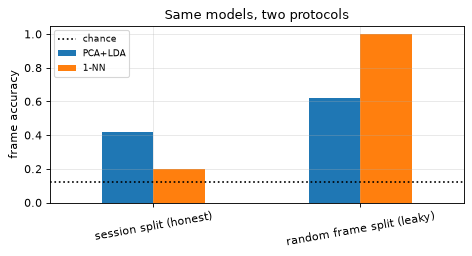

In [14]:
fig, ax = plt.subplots(figsize=(6, 3.3)); res.plot.bar(ax=ax, rot=10)
ax.axhline(1 / sc.n_directions, c="k", ls=":", label="chance"); ax.set(ylabel="frame accuracy", title="Same models, two protocols")
ax.legend(fontsize=8); plt.tight_layout(); plt.show()

The memorising model gains the most from the leak: with a random frame split almost every test
frame has a near-duplicate neighbour (same trial, 100 ms apart) in train. The low-capacity PCA +
LDA baseline is less affected, which is why a leak can go unnoticed with a simple model and
then surface as an inexplicable train/test gap after switching to a transformer. Numbers are
from this synthetic data at 8³ voxels and 4 sessions (about 4 s per trial); the *direction* of the effect is the
point, not its size.

## Pitfalls

* **Fitting anything on all data** (z-score, PCA, RETROICOR, feature selection, thresholds)
  before splitting. `fit_blocks` in the state makes this auditable.
* **Non-causal filtering** (zero-phase high-pass, centred moving average) in offline
  preprocessing: features then use the future and cannot be reproduced in the hot path.
* **Windows that straddle a block edge** pair train and test frames in one sequence;
  `make_windows` prevents it and `no_window_overlap` checks it.
* **Too-short gaps**: hemodynamic correlation lasts seconds; `gap_s` (10 s) separates blocks in
  `time_block` splits and `temporal_gap` enforces it.
* **Test-set reuse**: repeated looks at the test fold are a slow leak; `check_test_access`
  counts them per split hash.
* **Session-level shift**: gain differs per session (±8 % here), so a good held-out-session
  score also reflects robustness, not only generalisation within a session.

## Exercise

1. Change `hold_out` to `"subject"` with two simulated subjects and confirm `subjects_disjoint`
   becomes a required check. What does the headline score measure then?
2. Use `time_block` on a single session with `gap_s = 0`. Which check fails, and what does the
   accuracy of the 1-NN model do?
3. Add a causal 6-frame mean to the *preprocessor* (not the decoder) and check streaming equals
   batch again. What extra state does the hot path need?

In [15]:
import shutil
shutil.rmtree(WORK, ignore_errors=True)
print(f"done in {time.perf_counter() - T0:.1f}s; workspace removed")

done in 7.0s; workspace removed
